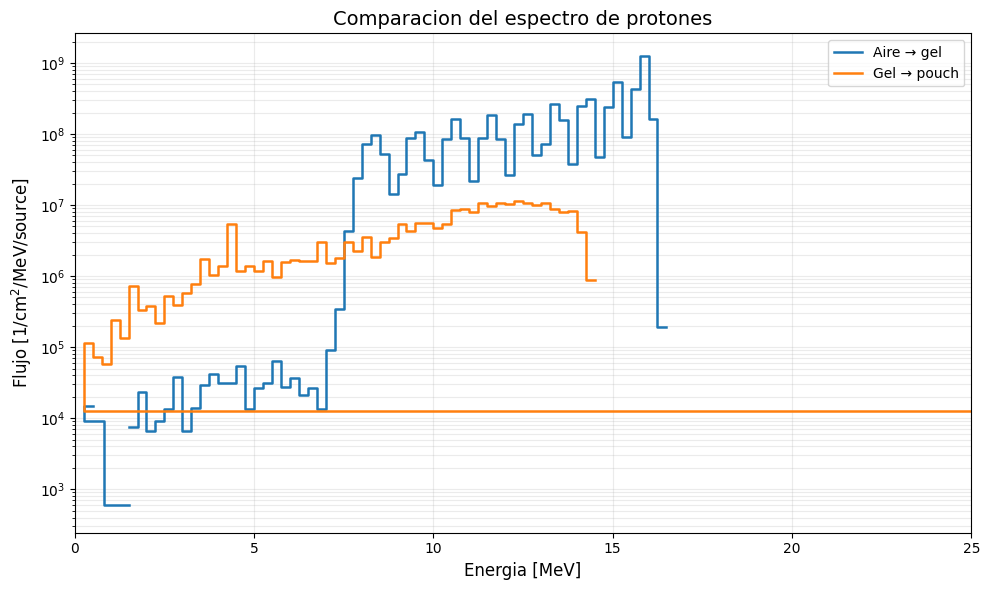

In [1]:

from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# ARCHIVOS
# ============================================================

carpeta = Path(r"D:\sin_oclusor_ni_dispersor_skinCONTODO")

archivo_airegel = carpeta / "espectro_aireagel.out"
archivo_gelapouch = carpeta / "espectro_gelapouch.out"


# ============================================================
# LEER ARCHIVOS T-CROSS DE PHITS
# ============================================================

def leer_tcross(archivo):

    if not archivo.exists():
        raise FileNotFoundError(f"No se encontro el archivo: {archivo}")

    energia = []
    flujo = []

    with archivo.open("r", encoding="utf-8", errors="ignore") as f:
        for linea in f:
            columnas = linea.split()

            if len(columnas) < 4:
                continue

            try:
                e_inf = float(columnas[0])
                e_sup = float(columnas[1])
                valor = float(columnas[2])
                error = float(columnas[3])
            except ValueError:
                continue

            if e_sup <= e_inf or e_inf < 0 or valor < 0:
                continue

            # Centro de cada intervalo de energia
            energia.append((e_inf + e_sup) / 2)
            flujo.append(valor)

    if not energia:
        raise ValueError(f"No se encontraron datos en {archivo}")

    return np.array(energia), np.array(flujo)


# ============================================================
# CARGAR ESPECTROS
# ============================================================

E_airegel, F_airegel = leer_tcross(archivo_airegel)
E_gelapouch, F_gelapouch = leer_tcross(archivo_gelapouch)


# ============================================================
# GRAFICAR COMPARACION
# ============================================================

fig, ax = plt.subplots(figsize=(10, 6))

# Evitar valores cero en el eje logaritmico
F_airegel_plot = np.where(F_airegel > 0, F_airegel, np.nan)
F_gelapouch_plot = np.where(F_gelapouch > 0, F_gelapouch, np.nan)

ax.step(
    E_airegel,
    F_airegel_plot,
    where="mid",
    linewidth=1.8,
    label="Aire → gel",
)

ax.step(
    E_gelapouch,
    F_gelapouch_plot,
    where="mid",
    linewidth=1.8,
    label="Gel → pouch",
)

ax.set_xlabel("Energia [MeV]", fontsize=12)
ax.set_ylabel(
    r"Flujo [1/cm$^2$/MeV/source]",
    fontsize=12,
)

ax.set_title("Comparacion del espectro de protones", fontsize=14)

ax.set_xlim(0, 25)
ax.set_yscale("log")

ax.grid(True, which="both", alpha=0.25)
ax.legend()
fig.tight_layout()

# Mostrar unicamente en el notebook
plt.show()


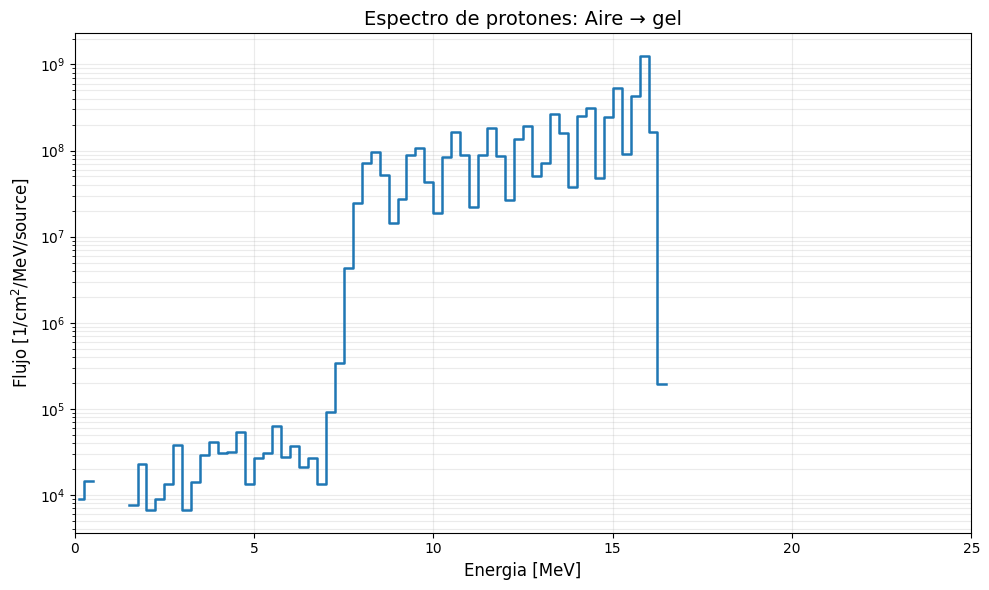

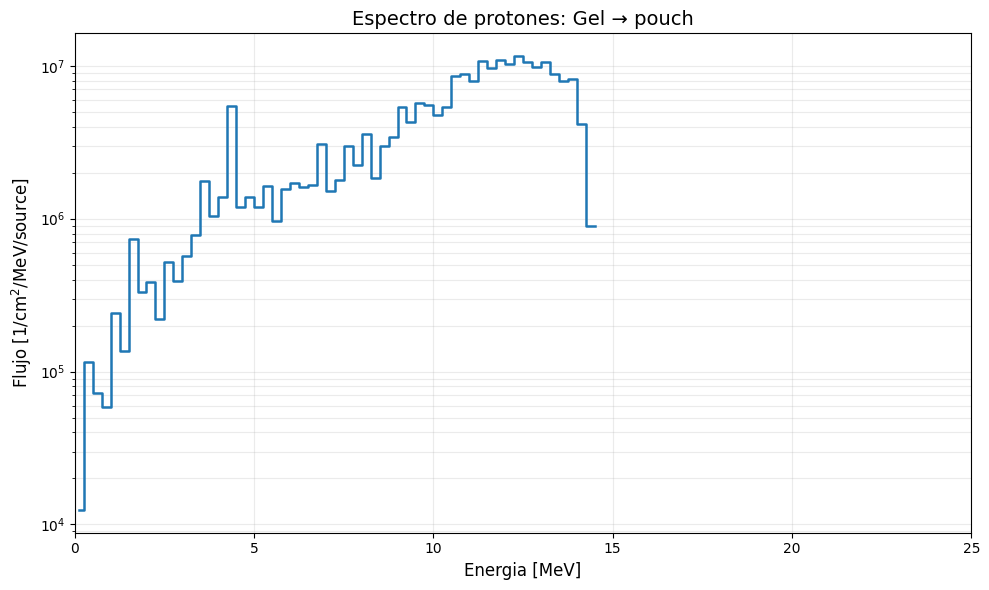

In [2]:

from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

# Carpeta de los archivos
carpeta = Path(r"D:\sin_oclusor_ni_dispersor_skinCONTODO")

archivo_airegel = carpeta / "espectro_aireagel.out"
archivo_gelapouch = carpeta / "espectro_gelapouch.out"


def leer_tcross(archivo):
    energia = []
    flujo = []
    leyendo_datos = False

    with archivo.open("r", encoding="utf-8", errors="ignore") as f:
        for linea in f:

            if "e-lower" in linea and "e-upper" in linea:
                leyendo_datos = True
                continue

            if not leyendo_datos:
                continue

            if "sum over" in linea:
                break

            columnas = linea.split()

            if len(columnas) < 4:
                continue

            try:
                e_inf, e_sup, valor, error = map(float, columnas[:4])
            except ValueError:
                continue

            if e_sup > e_inf and valor >= 0:
                energia.append((e_inf + e_sup) / 2)
                flujo.append(valor)

    if not energia:
        raise ValueError(f"No se encontraron datos en {archivo}")

    return np.array(energia), np.array(flujo)


# Leer los dos espectros
E_airegel, F_airegel = leer_tcross(archivo_airegel)
E_gelapouch, F_gelapouch = leer_tcross(archivo_gelapouch)


# ============================================================
# GRAFICO 1: AIRE -> GEL
# ============================================================

fig, ax = plt.subplots(figsize=(10, 6))

F_plot = np.where(F_airegel > 0, F_airegel, np.nan)

ax.step(
    E_airegel,
    F_plot,
    where="mid",
    linewidth=1.8,
)

ax.set_xlabel("Energia [MeV]", fontsize=12)
ax.set_ylabel(
    r"Flujo [1/cm$^2$/MeV/source]",
    fontsize=12,
)
ax.set_title("Espectro de protones: Aire → gel", fontsize=14)

ax.set_xlim(0, 25)
ax.set_yscale("log")
ax.grid(True, which="both", alpha=0.25)

fig.tight_layout()
plt.show()


# ============================================================
# GRAFICO 2: GEL -> POUCH
# ============================================================

fig, ax = plt.subplots(figsize=(10, 6))

F_plot = np.where(F_gelapouch > 0, F_gelapouch, np.nan)

ax.step(
    E_gelapouch,
    F_plot,
    where="mid",
    linewidth=1.8,
)

ax.set_xlabel("Energia [MeV]", fontsize=12)
ax.set_ylabel(
    r"Flujo [1/cm$^2$/MeV/source]",
    fontsize=12,
)
ax.set_title("Espectro de protones: Gel → pouch", fontsize=14)

ax.set_xlim(0, 25)
ax.set_yscale("log")
ax.grid(True, which="both", alpha=0.25)

fig.tight_layout()
plt.show()
